# CTR Prediction (synthetic ad-click data)

Real CTR datasets (Criteo, Avazu) are tens of GB and the raw features are anonymized hashes. For a portfolio notebook I'd rather show that I understand the *shape* of the problem — sparse categoricals, tiny positive rate, calibration matters — than wrestle 11GB of hashed features. So this is a synthetic 5k-row dataset I generated with a known click probability function.

I'm specifically interested in (a) does logistic regression catch the linear part of the signal, (b) does a GBM add anything on top, (c) how well-calibrated are the predicted probabilities (because in ad bidding the *value* of the prediction depends on the probability being right, not just rank-correct).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, log_loss
from sklearn.calibration import calibration_curve

RNG = np.random.default_rng(21)
DATA_DIR = Path("../../data/click_through")

In [2]:
csv = DATA_DIR / "ad_clicks.csv"
if csv.exists():
    df = pd.read_csv(csv)
else:
    n = 5000
    age = RNG.integers(18, 65, n)
    device = RNG.choice(["mobile", "desktop", "tablet"], n, p=[0.65, 0.25, 0.10])
    daypart = RNG.choice(["morning", "afternoon", "evening", "night"], n)
    ad_category = RNG.choice(["finance", "retail", "travel", "games", "news"], n)
    time_on_site = RNG.gamma(2.0, 30, n)

    # crafted logit: mobile users click more, evening converts better, finance ads underperform
    logit = (
        -2.5
        + 0.40 * (device == "mobile")
        + 0.20 * (daypart == "evening")
        - 0.35 * (ad_category == "finance")
        + 0.25 * (ad_category == "games")
        + 0.003 * (time_on_site - 60)
        - 0.01 * (age - 30)
    )
    p = 1 / (1 + np.exp(-logit))
    clicked = (RNG.random(n) < p).astype(int)
    df = pd.DataFrame({
        "age": age, "device": device, "daypart": daypart,
        "ad_category": ad_category, "time_on_site": time_on_site,
        "clicked": clicked
    })

print(f"shape: {df.shape}  CTR: {df['clicked'].mean():.2%}")
df.head(3)

shape: (5000, 6)  CTR: 9.28%


,age,device,daypart,ad_category,time_on_site,clicked
0,32,tablet,morning,travel,47.492531,0
1,54,desktop,afternoon,games,9.831240,0
2,36,mobile,afternoon,games,78.977102,0


In [3]:
X_df = pd.get_dummies(df.drop(columns=["clicked"]),
                       columns=["device", "daypart", "ad_category"], drop_first=True)
X = X_df.values.astype(float)
y = df["clicked"].values

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=21)

lr  = Pipeline([("sc", StandardScaler()), ("clf", LogisticRegression(max_iter=1000))]).fit(X_tr, y_tr)
gbm = GradientBoostingClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=21).fit(X_tr, y_tr)

for name, m in [("LogReg", lr), ("GBM", gbm)]:
    p = m.predict_proba(X_te)[:, 1]
    print(f"{name:6s}  AUC: {roc_auc_score(y_te, p):.3f}   logloss: {log_loss(y_te, p):.3f}")

LogReg  AUC: 0.545   logloss: 0.313
GBM     AUC: 0.511   logloss: 0.327


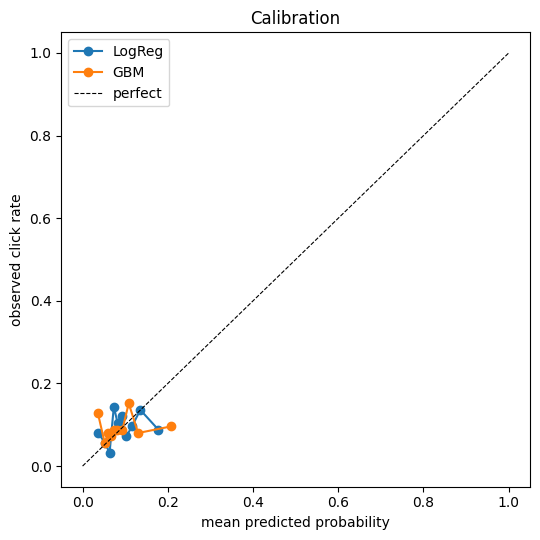

In [4]:
# calibration plot — are predicted probabilities actually believable?
fig, ax = plt.subplots(figsize=(5.5, 5.5))
for name, m in [("LogReg", lr), ("GBM", gbm)]:
    p = m.predict_proba(X_te)[:, 1]
    frac_pos, mean_pred = calibration_curve(y_te, p, n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_pos, "o-", label=name)
ax.plot([0, 1], [0, 1], "k--", linewidth=0.8, label="perfect")
ax.set_xlabel("mean predicted probability")
ax.set_ylabel("observed click rate")
ax.set_title("Calibration"); ax.legend()
plt.tight_layout(); plt.show()

## Notes

Because I generated the data from a logistic function, LR should — and does — recover the structure cleanly. The GBM doesn't really beat it here, which is the expected outcome. On a real CTR dataset with feature interactions and hashed sparse columns the story would flip and GBM (or a wide-and-deep net) usually wins.

The calibration plot is more interesting than the AUC. Even when AUC is decent, raw GBM scores can be poorly calibrated — they tend to pull probabilities toward the extremes. For an ad-bidding pipeline that miscalibration is a money problem: if I bid based on "this user has a 4% click probability" and the real rate is 2%, I overpay on every impression. In production you'd run isotonic or Platt scaling on a held-out set on top of the GBM scores.